# RemitRight LA
### CHIRLA · “Know what you really pay” campaign research
Compare historical U.S. remittance quotes, document community relevance, and export an offline briefing. **Staff decide priorities.** No personal member records. Mexico is illustrative, not a recommendation.

Run the startup cell once per session. Edit and execute the choices cell, then run the analysis cell. Historical quotes require current-price and community checks before publishing.

In [2]:
from pathlib import Path
from IPython.display import display, HTML, FileLink, clear_output
import pandas as pd
from src.contracts import ScoringWeights, validate_choices, period_key
from src.load_data import load_data, load_preparation_metadata
from src.load_relevance import load_relevance
from src.notebook_workflow import NotebookSession

clear_output(wait=False)
if "session" in globals():
    session.current_run_valid = False
prepared_path = "data/rpw_usa_clean.csv.gz"
preparation = load_preparation_metadata(prepared_path + ".validation.json", prepared_path)
quotes = load_data(prepared_path, preparation)
validate_choices(quotes)
available_periods = sorted(quotes["period"].unique(), key=period_key, reverse=True)
available_destinations = quotes[["destination_code", "destination_name"]].drop_duplicates().sort_values(["destination_name", "destination_code"], kind="stable")
print("Available survey quarters (newest first):", [p[:4] + " Q" + p[5] for p in available_periods])
display(available_destinations.reset_index(drop=True))
relevance_inputs = load_relevance("inputs/community_relevance.csv", set(quotes.destination_code))
session = NotebookSession(quotes, preparation)
print(f"Loaded once: {len(quotes):,} quotes. Relevance rows: {len(relevance_inputs)}")

Available survey quarters (newest first): ['2025 Q3', '2025 Q1', '2024 Q4', '2024 Q3', '2024 Q2', '2024 Q1', '2023 Q4', '2023 Q3', '2023 Q2', '2023 Q1', '2022 Q4', '2022 Q3', '2022 Q2', '2022 Q1', '2021 Q4', '2021 Q3', '2021 Q2', '2021 Q1', '2020 Q4', '2020 Q3', '2020 Q2', '2020 Q1', '2019 Q4', '2019 Q3', '2019 Q2', '2019 Q1', '2018 Q4', '2018 Q3', '2018 Q2', '2018 Q1', '2017 Q4', '2017 Q3', '2017 Q2', '2017 Q1', '2016 Q4', '2016 Q3', '2016 Q2']


,destination_code,destination_name
0,AFG,Afghanistan
1,ARM,Armenia
2,BGD,Bangladesh
3,BRA,Brazil
4,CPV,Cabo Verde
5,CHN,China
6,COL,Colombia
7,CRI,Costa Rica
8,CUB,Cuba
9,DOM,Dominican Republic


Loaded once: 29,542 quotes. Relevance rows: 0


## Researcher choices
Empty period/destination lists request **All available**. Choose exactly one amount, 200 or 500. Relevance is separate researcher judgment: edit `inputs/community_relevance.csv` using rating 0–5 plus rationale, source and YYYY-MM-DD date, then explicitly rerun its load line below. Missing or partial documentation remains unavailable; descriptive evidence still works.

Notebook edits take effect only when the cell is executed. Changing presentation-only `provider_preview_rows` does not invalidate a matching successful analysis.

In [3]:
periods = [available_periods[0]]
destination_codes = ["MEX"]
transfer_amount_usd = 200
weights = ScoringWeights(cost=0.50, transparency=0.25, relevance=0.25)
provider_preview_rows = 100
# Execute this line explicitly after editing the relevance CSV:
# relevance_inputs = load_relevance("inputs/community_relevance.csv", set(quotes.destination_code))

## Current briefing
A failed run clears the previous display and prevents export; the last successful bundle and its independent snapshot remain stored for inspection. Rendering uses the current result bundle and a disclosed provider preview. HTML export includes every matching service row.


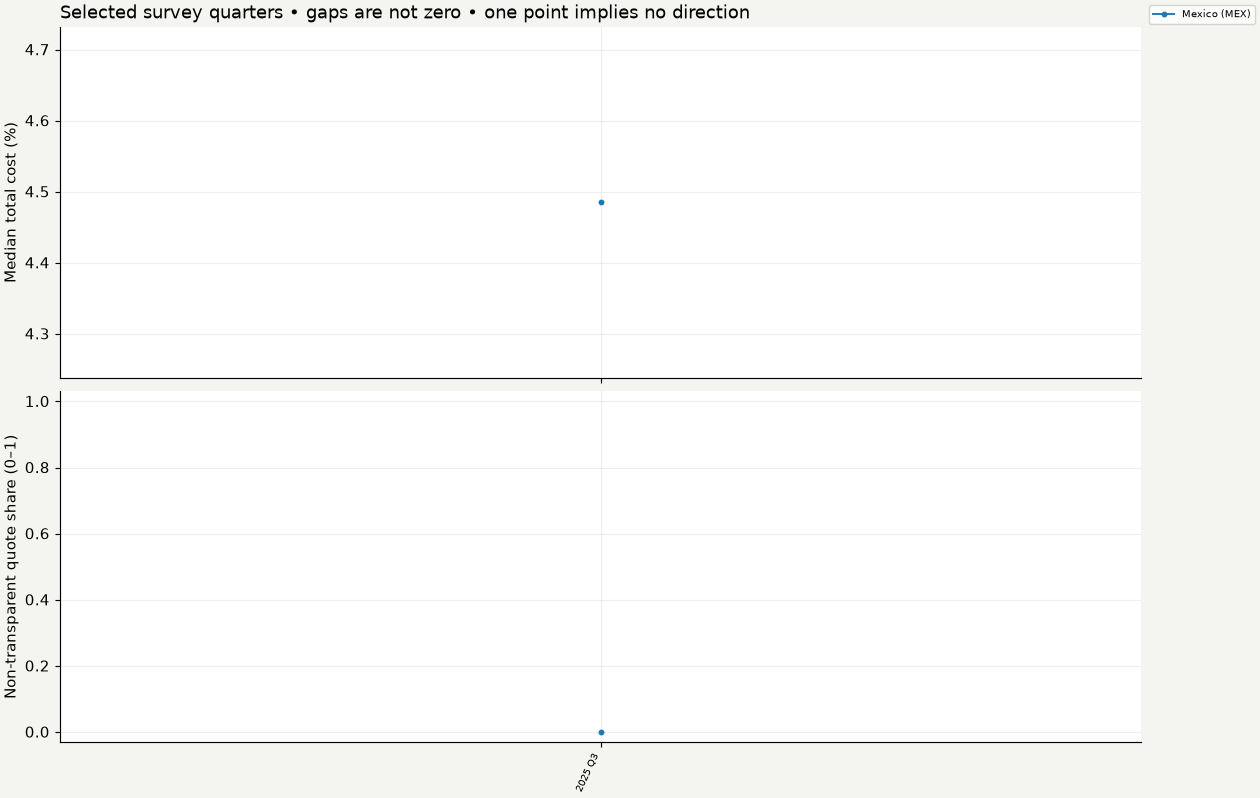

In [4]:
results = session.analyze(periods, destination_codes, transfer_amount_usd,
                          weights, relevance_inputs, provider_preview_rows)

## Export the exact current analysis
Export occurs only on an explicit request. **Set `export_requested = True` and execute this cell.** The guard compares current executed period/destination choices, amount, weights, validated relevance and prepared fingerprint with the successful analysis snapshot. Changed or invalid inputs require a successful analysis rerun. Editing an input cell changes nothing until it is executed. The export guard reads no files and performs no calculation. Outputs stay local; no automatic sharing.

In [ ]:
export_requested = False
if export_requested:
    path = session.export(periods, destination_codes, transfer_amount_usd,
                          weights, relevance_inputs)
    display(FileLink(str(path)))
else:
    print("No export requested. Set export_requested = True to save an offline HTML briefing.")

## Limitations and source
Historical sampled quotes are not live prices. Quote counts are not customer counts or market shares. Survey composition changes; pooled-quarter medians give periods with more eligible quotes more observations. Scores use selection-relative normalization and documented subjective relevance. Missing zero-weight components remain missing and contribute zero without redistribution. One point implies no direction. Staff check current prices and community relevance before publishing.

**Remittance Prices Worldwide, World Bank Group**, [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/), [dataset](https://datacatalog.worldbank.org/search/dataset/0037898/Remittance-Prices-Worldwide). Adaptation: cleaned USA rows and derived summaries.